In [1]:
import numpy as np
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.plotting import plot_decision_regions

In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense , Dropout
from tensorflow.keras.optimizers import Adam

In [3]:
X , y = make_moons(n_samples=100, noise=0.24 , random_state=2)

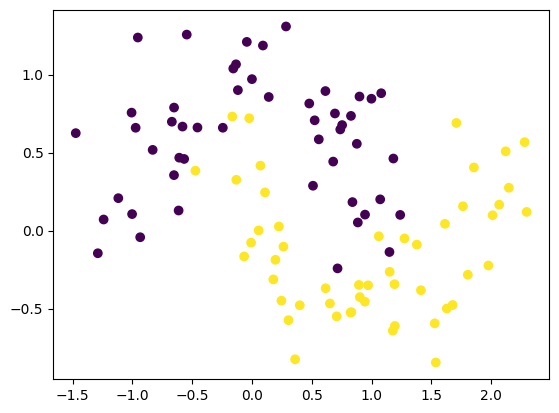

In [4]:
plt.scatter(X[:,0] , X[:,1] , c=y)
plt.show()

In [5]:
model = Sequential()
model.add(Dense(units=128 , activation='relu' , input_dim = 2))
model.add(Dense(units=128 , activation='relu'))
model.add(Dense(units=1 , activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [6]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,025 (66.50 KB)

 Trainable params: 17,025 (66.50 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
adam = Adam(learning_rate=0.02)
model.compile(optimizer=adam  , metrics=['accuracy'] , loss = 'binary_crossentropy')

In [8]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train , y_test = train_test_split(X , y ,test_size=0.2 , random_state=43)

In [9]:
history = model.fit(X_train , y_train , validation_data = (X_test , y_test ) , epochs=1000 , verbose=0)

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 13s 1ms/step


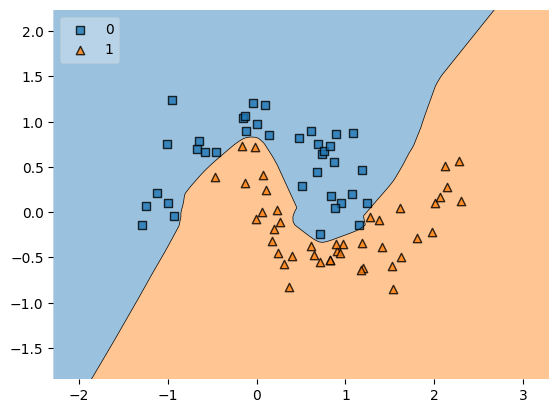

In [11]:
plot_decision_regions(X = X_train , y = y_train.astype('int') , clf=model , legend=2)
plt.show()

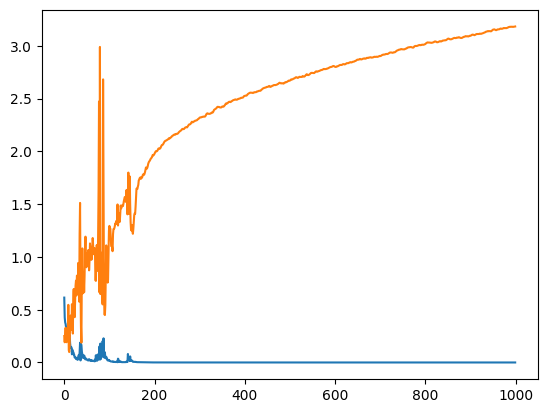

In [13]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.show()

**Using Regularization**

In [20]:
model1 = Sequential()
model1.add(Dense(units = 128  , activation= 'relu' , input_dim = 2 , kernel_regularizer=tf.keras.regularizers.l2(0.05)))
model1.add(Dense(units = 128  , activation= 'relu' , kernel_regularizer=tf.keras.regularizers.l2(0.03)))
model1.add(Dense(units = 1  , activation= 'sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [21]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,077 (199.52 KB)

 Trainable params: 17,025 (66.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 34,052 (133.02 KB)

In [27]:
adam = Adam(learning_rate=0.02)
model1.compile(optimizer=adam  , metrics=['accuracy'] , loss = 'binary_crossentropy')

In [28]:
history1 = model1.fit(x = X_train , y = y_train , validation_data = (X_test , y_test ) , verbose=0 , epochs=1000)

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 13s 1ms/step


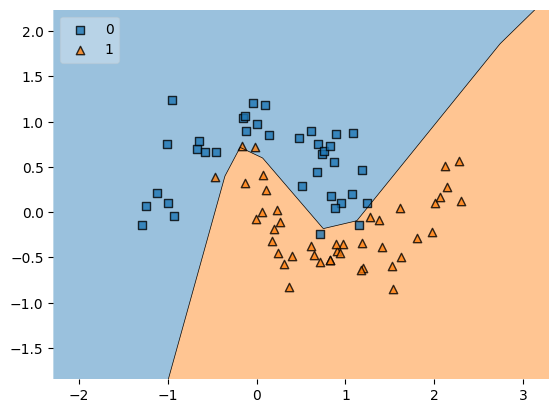

In [29]:
plot_decision_regions(X = X_train , y = y_train.astype('int') , clf=model1 , legend=2)
plt.show()

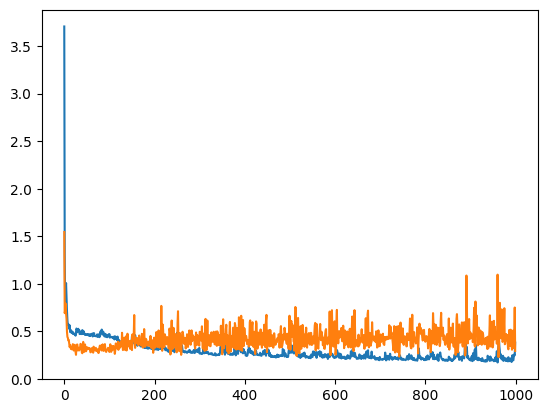

In [31]:
plt.plot(history1.history['loss'])
plt.plot(history1.history['val_loss'])
plt.show()

In [38]:
model1_w_layer1 = model1.get_weights()[0].reshape(256)
model_w_layer1= model.get_weights()[0].reshape(256)

<Axes: >

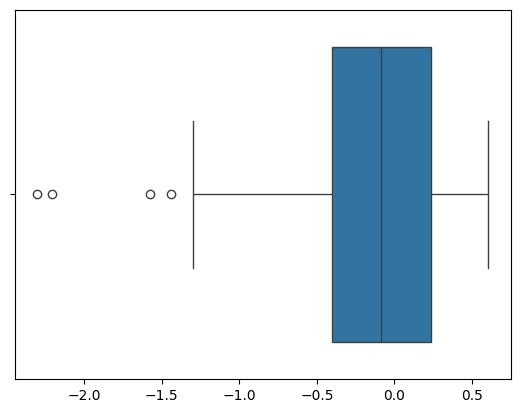

In [40]:
sns.boxplot(model_w_layer1 ,  orient='h')

<Axes: >

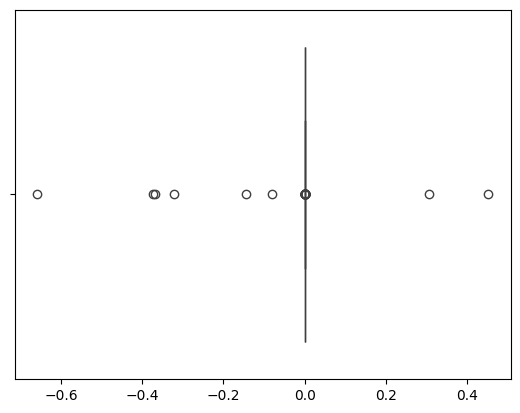

In [41]:
sns.boxplot(model1_w_layer1 , orient = 'h')

In [42]:
print(f"Model (without regularization) weights min val = {model_w_layer1.min()} and max val = {model_w_layer1.max()}")
print(f"Model (with regularization) weights min val = {model1_w_layer1.min()} and max val = {model1_w_layer1.max()}")

Model (without regularization) weights min val = -2.3011038303375244 and max val = 0.6056600213050842
Model (with regularization) weights min val = -0.6579933166503906 and max val = 0.45238038897514343


/tmp/ipykernel_2754/4057208023.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(model_w_layer1 , label='Model (without regularization)')
/tmp/ipykernel_2754/4057208023.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(model1_w_layer1 , label='Model (with regularization)')


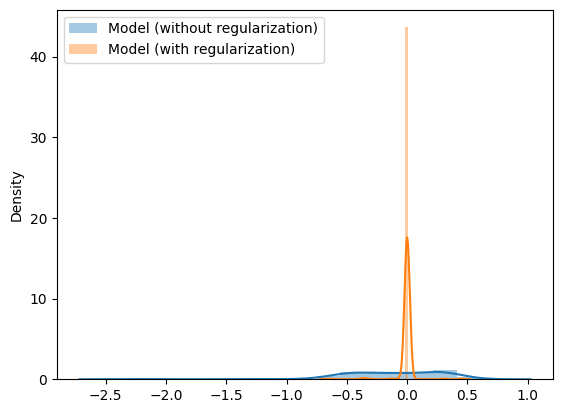

In [50]:
sns.distplot(model_w_layer1 , label='Model (without regularization)')
sns.distplot(model1_w_layer1 , label='Model (with regularization)')
plt.legend()
plt.show()